# 07 · Statistics: Table 4, Table 5, Figures 3–5 (Results 4.3–4.5)
Friedman per model (seeds as blocks) → where significant, Holm-corrected Wilcoxon signed-rank (paired by seed, `zero_method="wilcox"`) with rank-biserial effect sizes → Kendall's τ.

Notes: Holm is applied within each model (10 pairs). Wilcoxon p-values use scipy's default (exact when there are no ties or zero differences, otherwise the normal approximation). With only 5 methods, Kendall's τ is read descriptively.

In [1]:
import os
from pathlib import Path
import pandas as pd
from IPython.display import display
from hpo import config, data, spaces, starts, methods, runner, stats, plots

pd.set_option("display.precision", 5)
# Results folder: the full run by default. Set HPO_RESULTS=smoke to read the smoke test.
RESULTS = (
    config.SMOKE_DIR if os.environ.get("HPO_RESULTS") == "smoke" else config.RESULTS_DIR
)
FIGS, TABLES = RESULTS / "figures", RESULTS / "tables"
TABLES.mkdir(parents=True, exist_ok=True)
print("Reading/writing:", RESULTS.relative_to(config.ROOT))

Reading/writing: results


## Table 4 · Friedman test per model

In [2]:
runs, _ = stats.load(RESULTS)
fr = stats.friedman(runs)
fr.to_csv(TABLES / "table4_friedman.csv")
fr

,n_seeds,k_methods,chi2,p,significant
model,,,,,
svm,20,5,60.76768,2.00066e-12,True
rf,20,5,35.32000,3.99274e-07,True
xgb,20,5,53.24000,7.59110e-11,True


## Table 5 · Holm-Wilcoxon pairs and rank-biserial effect sizes (models with a significant Friedman test)

In [3]:
pw = stats.pairwise_all(runs)
pw.to_csv(TABLES / "table5_pairwise.csv", index=False)
print("Post-hoc run for:", sorted(set(pw["model"])) if len(pw) else "none")
pw.round(4)

Post-hoc run for: ['rf', 'svm', 'xgb']


,model,a,b,mean_diff,p,r_rb,p_holm,significant
0,svm,grid,random,-0.0002,0.0001,-1.0000,0.0005,True
1,svm,grid,ga,-0.0001,0.0973,-0.4286,0.1946,False
2,svm,grid,de,-0.0007,0.0000,-1.0000,0.0000,True
3,svm,grid,pso,-0.0008,0.0000,-1.0000,0.0000,True
4,svm,random,ga,0.0001,0.0586,0.4947,0.1757,False
5,svm,random,de,-0.0005,0.0000,-0.9714,0.0001,True
6,svm,random,pso,-0.0006,0.0002,-0.9789,0.0008,True
7,svm,ga,de,-0.0006,0.0000,-1.0000,0.0000,True
8,svm,ga,pso,-0.0007,0.0002,-0.9895,0.0008,True
9,svm,de,pso,-0.0001,0.2162,-0.3238,0.2162,False


## Figure 3 · Pairwise effect sizes (significant cells marked *)

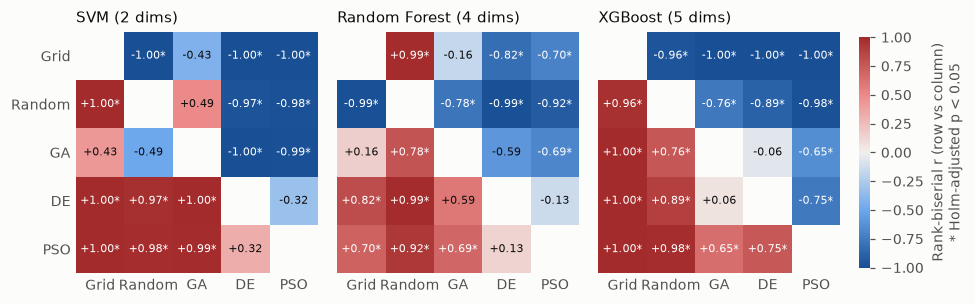

In [4]:
fig = plots.fig_pairwise_heatmap(pw)
plots.save(fig, FIGS, "fig3_pairwise_heatmap")

## Figure 4 · Gains over Random and over Grid as dimensions grow (RQ2)

,baseline,model,dims,method,gain_mean,ci_low,ci_high
0,random,svm,2,grid,-0.0002,-0.0003,-0.0001
1,random,svm,2,ga,-0.0001,-0.0002,-0.0000
2,random,svm,2,de,0.0005,0.0003,0.0006
3,random,svm,2,pso,0.0006,0.0004,0.0007
4,random,rf,4,grid,0.0004,0.0003,0.0005
5,random,rf,4,ga,0.0004,0.0002,0.0007
6,random,rf,4,de,0.0008,0.0005,0.0010
7,random,rf,4,pso,0.0008,0.0005,0.0011
8,random,xgb,5,grid,-0.0015,-0.0020,-0.0010
9,random,xgb,5,ga,0.0014,0.0007,0.0021


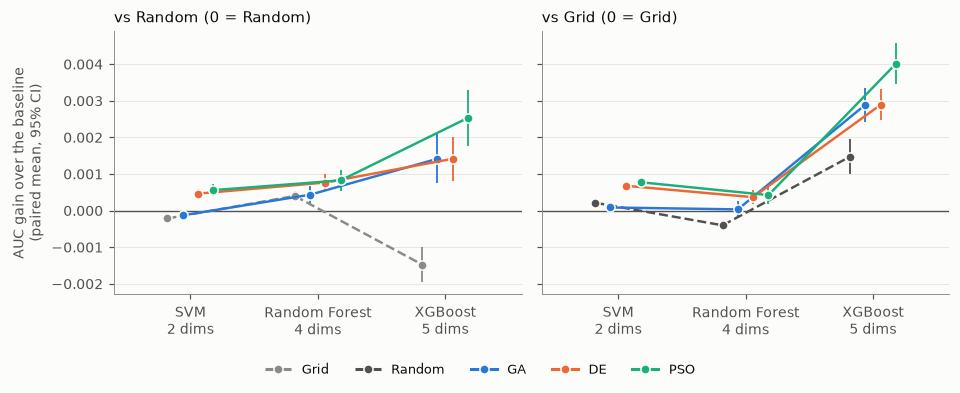

In [5]:
g4 = pd.concat(
    [stats.gains(runs, "random"), stats.gains(runs, "grid")], ignore_index=True
)
g4.to_csv(TABLES / "fig4_gains.csv", index=False)
fig = plots.fig_gains(g4)
plots.save(fig, FIGS, "fig4_gains")
g4.round(4)

## Figure 5 · Do the rankings agree across models? (RQ3)

,svm,rf,xgb
method,,,
grid,4.65,3.15,4.90
random,3.25,4.60,3.60
ga,3.90,3.15,2.60
de,1.65,2.10,2.35
pso,1.55,2.00,1.55


,pair,tau,p
0,svm–rf,0.527,0.207
1,svm–xgb,0.800,0.083
2,rf–xgb,0.738,0.077


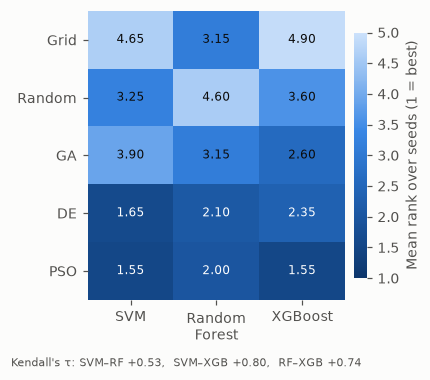

In [6]:
ranks = stats.mean_ranks(runs)
tau = stats.kendall(ranks)
ranks.to_csv(TABLES / "fig5_mean_ranks.csv")
tau.to_csv(TABLES / "fig5_kendall.csv", index=False)
fig = plots.fig_rank_heatmap(ranks, tau)
plots.save(fig, FIGS, "fig5_rank_heatmap")
display(ranks.round(2))
tau.round(3)